# Image Spatter — V1'de ne yapmak istiyoruz?

**Proje anlatımı / Project overview**

Amacımız, bir fotoğraftaki olası düzenleme izlerine daha yakından bakmayı sağlayan küçük bir masaüstü uygulaması yapmak. Kullanıcı bir görüntü açacak, bir analiz çalıştıracak ve çıkan sonucu fotoğrafla birlikte inceleyecek.

Bu notebook, projeyi anlatırken takip edebileceğimiz kısa bir not. Kod çalıştırmadan okunabilir; temsili çizimler dosyanın içinde. Burada tamamlamayı hedeflediğimiz ilk sürümü, yani **V1 Academic MVP** kapsamını anlatıyoruz.


## Neden böyle bir araç yapıyoruz?

Bir fotoğrafa parça eklenmiş, bir nesne silinmiş veya aynı alan başka yere kopyalanmış olabilir. Bunları yalnızca fotoğrafa bakarak anlamak her zaman kolay değildir.

Biz görüntünün içindeki bazı sayısal özellikleri görünür hale getireceğiz. Kullanıcı da “burada farklı görünen bir şey var mı?” diye fotoğrafı daha ayrıntılı inceleyebilecek. Sonuç ekranında gördüğümüz farkın ne anlama geldiğini açıkça anlatacağız.

**Hedefimiz:** Kesin bir gerçek/sahte hükmü vermek yerine incelemeyi kolaylaştıran görseller sunmak.


## Kullanıcı ne yapacak?

1. Bilgisayarından bir fotoğraf açacak.
2. Kullanılabilir bir analiz yöntemini seçip **Analizi çalıştır** diyecek.
3. Fotoğrafı ve analiz sonucunu yan yana görecek.
4. Yöntem uygunsa bir ayarı değiştirip farkın nasıl değiştiğine bakabilecek.

Örneğin ELA kullanırsak, yeniden JPEG kaydetme kalitesini değiştirebilecek. Başka bir yöntem seçilirse onun anlamlı ayarlarını göstereceğiz. Görüntüler kullanıcının bilgisayarında işlenecek; analiz için buluta yüklenmeyecek.


## Ekranı şöyle düşünebiliriz

Solda seçilen fotoğraf, sağda analiz sonucu olacak. Üstte fotoğraf açma ve analizi başlatma gibi birkaç temel kontrol bulunacak. İlk sürümde bu akışı çalışır hale getirmeye odaklanacağız.

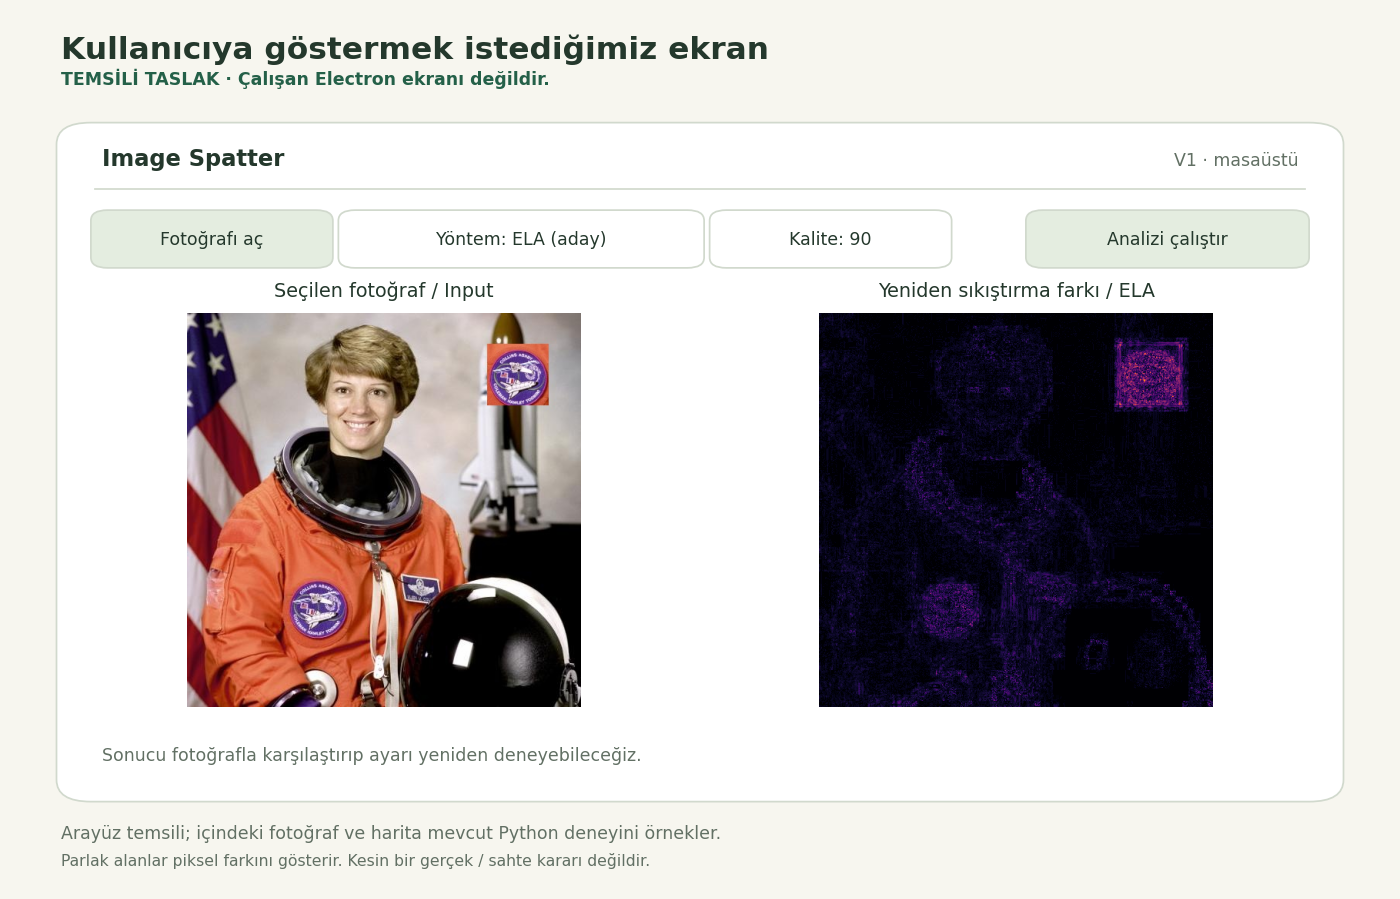

Bu bir **arayüz taslağı / mockup**. İçindeki görüntüler mevcut Python ELA denemesini örnekliyor; çalışan Electron arayüzü gösterdiğimiz anlamına gelmiyor.


## Peki görüntüde neye bakacağız?

Şu an ELA ile bir ilk denememiz var. Ama V1 planında tek bir yöntem henüz kesinleşmiş değil. Ön denemelerde neyin işe yaradığına ve yetiştirilebilir olduğuna bakıp karar vereceğiz.

| Aday yöntem | Basitçe ne yapıyor? |
|---|---|
| **ELA — Error Level Analysis** | Fotoğrafı tekrar JPEG olarak kaydedip piksel değerlerinde oluşan farkları gösteriyor. |
| **Gürültü analizi — Noise analysis** | Görüntünün bölgelerindeki ince pütürlerin farklı davranıp davranmadığına bakıyor. |
| **Copy-move incelemesi** | Aynı fotoğrafın içinde birbirine benzeyen, kopyalanmış olabilecek parçaları araştırıyor. |

İlk teslim için bu yöntemlerin hepsini bitirmeyi taahhüt etmiyoruz. **En az bir çalışan yöntem** seçip sonucunu anlaşılır biçimde göstereceğiz. Örneğin ELA'da parlak bir alanın tek başına düzenleme kanıtı olmadığını da açıklayacağız.


## Bunu nasıl kuracağız?

**Electron**, kullanıcının gördüğü masaüstü penceresini oluşturacak. **Python + OpenCV**, fotoğrafı işleyen taraf olacak. Aralarındaki yerel bağlantı da görüntüyü, seçilen ayarları ve sonuçları taşıyacak.

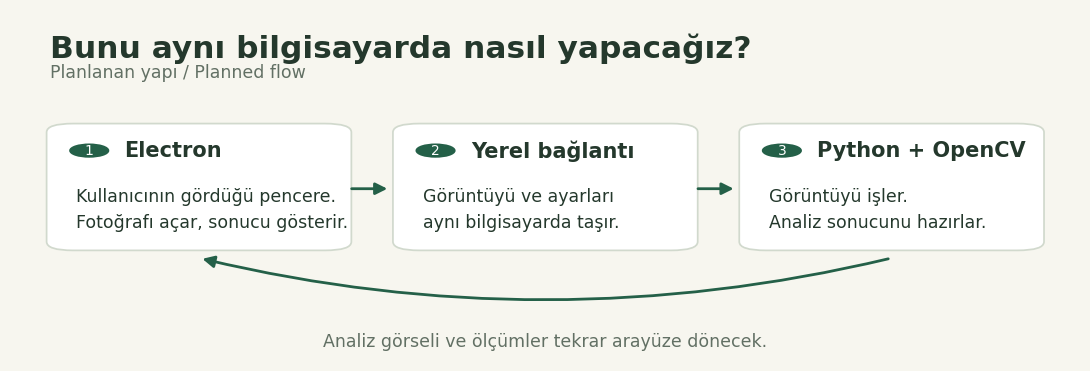

Kullanıcı bu parçalar arasında elle dosya taşımayacak. Fotoğrafı açıp analizi başlattığında uygulama bu işleri arka planda yapacak. Bağlantının teknik ayrıntısını ilk entegrasyon denemelerinde netleştireceğiz; özel GPU veya bulut servisi gerektirmeyen bir yapı hedefliyoruz.


## İlk sürümde hangi işleri tamamlayacağız?

| Yapacağımız iş | Kullanıcı bunu nasıl görecek? |
|---|---|
| Yerel görüntü açma | Dosyasını seçip fotoğrafı ekranda görebilecek. |
| Bir analiz yöntemini çalıştırma | Analizi başlatınca Python tarafı sonucu hazırlayacak. |
| Sonucu gösterme | Girdiyle işlenmiş görüntüyü veya analiz haritasını karşılaştırabilecek. |
| Temel etkileşim | Yönteme uygunsa bir parametreyi değiştirip tekrar deneyebilecek. |
| Değerlendirme ve karşılaştırma | Örnek görüntülerde ne gördüğümüzü ve hangi ayarı kullandığımızı raporlayacağız. |

Gelişmiş çoklu pencere düzenleri, otomatik raporlar ve oyunlaştırma sonraki sürümün fikirleri. V1'in merkezinde fotoğrafı açma → analiz → sonucu inceleme akışı var.


## “Çalışıyor” derken neye bakacağız?

Önce düzenlemediğimiz bir kontrol görüntüsü kullanacağız. Sonra ona, yerini bildiğimiz küçük bir düzenleme yapacağız. Böylece analiz sonucunu elimizdeki bilgiyle karşılaştırabileceğiz. Bunu birden fazla örnekle deneyeceğiz.

**Süreyi** ölçeceğiz: bir analizin kaç milisaniye sürdüğünü kaydedeceğiz. **Yönteme uygun ölçümlere** bakacağız: örneğin ELA'da bilinen bölgelerdeki farkları karşılaştırabiliriz. Bir yöntem bölge işaretliyorsa doğru ve yanlış işaretlemelerine de bakabiliriz.

Ayrıca aynı yöntemin farklı ayarlarını ya da uygun bir alternatif yöntemi karşılaştıracağız. ELA seçilirse aynı fotoğrafı **5, 10 ve 20 gibi çok düşük** JPEG kalitelerinde de deneyeceğiz. **40 ve 60** ara değerleriyle **80, 90 ve 95** yüksek değerlerini karşılaştıracağız. Böylece kalite iyice düşünce normal görüntü bölgelerinin de ne kadar etkilendiğine bakacağız. Hangi denemenin neden karşılaştırılabilir olduğunu raporda açıklayacağız.

Normal bir dokunun dikkat çekmesi veya bilinen düzenlemenin görünmemesi gibi yanıltan örnekleri de not edeceğiz. Renkli bir haritaya bakıp “başarı oranımız şu kadar” demeyeceğiz; kullandığımız ölçütün ne anlattığını belirteceğiz.


## Yedi haftayı nasıl kullanacağız?

| Dönem | Yapmayı planladığımız iş |
|---|---|
| **1–2. haftalar** | Yöntemleri araştıracağız, projeyi kuracağız ve arayüzle Python arasında ilk bağlantıyı deneyeceğiz. |
| **3–4. haftalar** | Temel analizi çalıştırıp küçük bir prototip oluşturacağız. |
| **5–6. haftalar** | Arayüzle analizi birleştirecek, örnekleri test edip karşılaştırmaları yapacağız. |
| **7. hafta** | Son düzeltmeleri, teknik raporu ve sunumu tamamlayacağız. |

İki ekip üyesi de araştırma, görüntü işleme, arayüz, entegrasyon, test ve dokümantasyon aşamalarında birlikte çalışacak. Bu tablo haftaların planı; tamamlanmış işler listesi değil.


## V1 ne zaman tamamlanmış sayılacak?

- [ ] Kullanıcı bir görüntüyü açabiliyor.
- [ ] Python tarafında en az bir analiz çalışıyor.
- [ ] Sonuç Electron penceresinde görüntüleniyor.
- [ ] Kontrollü örneklerde ölçümler ve anlamlı bir karşılaştırma sunabiliyoruz.
- [ ] Prototipi ders sunumunda baştan sona gösterebiliyoruz.

Teslimde çalışan prototipin yanında **test bulguları, teknik rapor ve sunum** da olacak. Mevcut ELA notebook'ları ilk Python denemesini gösteriyor; bu maddeler masaüstü V1 hedefinin tamamını tarif ediyor.


## Sunumda şöyle anlatabiliriz

> “Amacımız, fotoğraflardaki olası düzenleme izlerini incelemeyi kolaylaştıran bir masaüstü uygulaması yapmak. Kullanıcı fotoğrafını açacak, bir analiz çalıştıracak ve sonucu görüntüyle karşılaştıracak. Ekranı Electron ile, görüntü işlemeyi Python ve OpenCV ile hazırlayacağız. İlk sürümde en az bir çalışan yönteme odaklanacağız; şu an ELA'yı deniyoruz. Yöntemi kontrollü örneklerde test edip süreyi ve uygun ölçümleri raporlayacağız. Kesin bir gerçek/sahte kararı vermek yerine, kullanıcının inceleyebileceği sonuçlar göstereceğiz.”

Bu anlatımın dayanağı [Image Spatter V1 — Academic MVP planı](<../Image Processing Project sensitive content/Image_Spatter_V1_Academic_MVP.md>). Temsili ekran ve akış, o plandaki ilk sürüm hedeflerini somutlaştırmak için eklendi.
